In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = '7'

import numpy as np
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["MKL_THREADING_LAYER"] = "GNU"
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import random
from tqdm import tqdm
from shapely.affinity import translate, scale
import shapely.geometry
from shapely import affinity
from shapely.geometry import (
    Polygon, MultiPolygon, LineString, MultiLineString, Point, MultiPoint, GeometryCollection
)
from shapely.geometry.base import BaseGeometry
import argparse

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import torch
from torch.utils.data import Dataset

import sys
# sys.path.append('/home/users/chen/2024/Global/utils')
# import utils
# import importlib
# importlib.reload(utils)

#/home/users/chen/2024/NeuralRep
sys.path.append('/home/chenchu/projects/Global')
from utils import visualization
sys.path.append('/home/chenchu/projects')
sys.path.append('/home/chenchu/projects/GeoNeuralRepresentation') #/GeoNeuralRepresentation
#from GeoNeuralRepresentation import list2embedding
import GeoNeuralRepresentation
from GeoNeuralRepresentation.runners import list2embedding
from GeoNeuralRepresentation.utils import test_representation
# from models import Geo2Vec

# sys.path.append('/home/users/chen/2024/Global/utils_global')
# import utils_global
# import importlib
# importlib.reload(utils_global)

import collections 
import json

In [2]:
city = 'LosAngeles'#'LosAngeles'
path = '/home/chenchu/projects/LLMs/urban/data/osm/'+city+'/'
save_file_name = path + city + '_embeddings_self.npy'
save_model_path = path + city + '_geo2vec_model_self.pth'

gdf_source = gpd.read_file(path + 'all_osm_with_names.gpkg')
Geolist = gdf_source['geometry'].tolist()

In [3]:
city = 'Beijing'#'LosAngeles'
path = '/home/chenchu/projects/LLMs/urban/data/osm/'+city+'/'
save_file_name = path + city + '_embeddings_self.npy'
save_model_path = path + city + '_geo2vec_model_self.pth'

gdf_target = gpd.read_file(path + 'all_osm_with_names.gpkg')
Geolist = gdf_target['geometry'].tolist()
print(gdf_target.head())

                        name  \
0                中国人民革命军事博物馆   
1                     先农坛体育场   
2                   凤凰国际传媒中心   
3                       建国宾馆   
4  Sanlitun Soho Building 12   

                                            geometry  
0  POLYGON ((441585.032 4417710.908, 441587.644 4...  
1  POLYGON ((447738.341 4413850.311, 447739.506 4...  
2  POLYGON ((454479.639 4420548.933, 454493.892 4...  
3  POLYGON ((452616.331 4417659.601, 452616.417 4...  
4  POLYGON ((452716.227 4420341.526, 452711.02 44...  


In [4]:
# bounding box for gdf_target
minx, miny, maxx, maxy = gdf_target.total_bounds
print(f"Bounding box: ({minx}, {miny}, {maxx}, {maxy})")
print(maxx - minx, maxy - miny)
# bounding box for gdf_source
minx, miny, maxx, maxy = gdf_source.total_bounds
print(f"Bounding box: ({minx}, {miny}, {maxx}, {maxy})")
print(maxx - minx, maxy - miny)

Bounding box: (428004.6673490335, 4402511.738302352, 467376.63586471556, 4440539.984708723)
39371.968515682034 38028.246406370774
Bounding box: (360125.9683379771, 3739124.577010211, 396237.47831892385, 3777556.80985865)
36111.50998094678 38432.2328484389


In [5]:
def normalize_geometries(polys_list, size=None):
    """
    Normalize all the polygons in the list to (-1,1)
    Keep distance relationship invariant
    """
    # Step 1: Get total bounds
    all_bounds = [geom.bounds for geom in polys_list]
    min_x = min(b[0] for b in all_bounds)
    min_y = min(b[1] for b in all_bounds)
    max_x = max(b[2] for b in all_bounds)
    max_y = max(b[3] for b in all_bounds)

    width = max_x - min_x
    height = max_y - min_y

    # Avoid division by zero
    if width == 0:
        width = 1e-9
    if height == 0:
        height = 1e-9

    if size is not None:
        width, height = size


    normalized_dict = []
    # Step 2: Normalize each geometry
    for geom in polys_list:
        # Translate to origin
        translated = translate(geom, xoff=-min_x, yoff=-min_y)
        # Scale to unit square
        normalized = scale(translated, xfact=1 / width, yfact=1 / height, origin=(0, 0))
        normalized_dict.append(normalized)
    return normalized_dict, (width, height)
normalized_source_geoms, (source_width, source_height) = normalize_geometries(gdf_target['geometry'].tolist())

normalized_target_geoms, (target_width, target_height) = normalize_geometries(gdf_source['geometry'].tolist(), size=(source_width, source_height))


<Axes: >

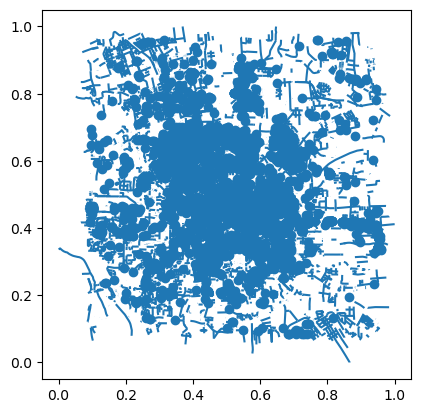

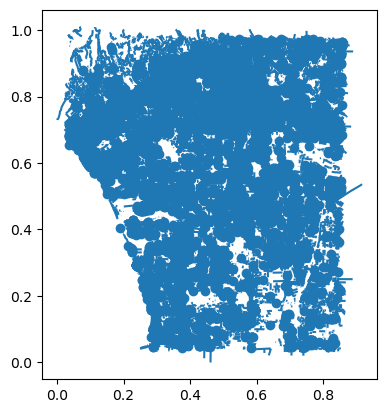

In [6]:
normalized_source_geoms_dataframe = gpd.GeoDataFrame(geometry=normalized_source_geoms)
normalized_target_geoms_dataframe = gpd.GeoDataFrame(geometry=normalized_target_geoms)
normalized_source_geoms_dataframe.plot()
normalized_target_geoms_dataframe.plot()

In [7]:
def get_args():
    parser = argparse.ArgumentParser(description="Geo2vec Training Config")

    # file_path: where the data is stored in pkl or gpkg format
    file_path = r'data\ShapeClassification.gpkg'
    parser.add_argument('--file_path', type=str, default=file_path)
    # Save file path
    save_path = os.path.splitext(file_path)[0] + '.pth'
    parser.add_argument('--save_file_name', type=str, default=save_path)
    num_process = 64

    # Sampling Parameters
    # For location
    parser.add_argument('--num_process', type=int, default=num_process)
    parser.add_argument('--samples_perUnit_location', type=int, default=1000000) #00
    parser.add_argument('--point_sample_location', type=int, default=50)
    parser.add_argument('--sample_band_width_location', type=float, default=0.05)
    parser.add_argument('--uniformed_sample_perUnit_location', type=int, default=50)

    # For shape
    parser.add_argument('--samples_perUnit_shape', type=int, default=10) #100
    parser.add_argument('--point_sample_shape', type=int, default=5) #20
    parser.add_argument('--sample_band_width_shape', type=float, default=0.1)
    parser.add_argument('--uniformed_sample_perUnit_shape', type=int, default=5) #20

    # Training parameters
    # For location
    parser.add_argument('--batch_size', type=int, default=1024 * 20)
    parser.add_argument('--num_workers', type=int, default=16)  # Training dataload number of works

    parser.add_argument('--epochs_location', type=int, default=5)
    parser.add_argument('--num_layers_location', type=int, default=8)
    parser.add_argument('--z_size_location', type=int, default=256)
    parser.add_argument('--hidden_size_location', type=int, default=256)
    parser.add_argument('--num_freqs_location', type=int, default=16)
    parser.add_argument('--device', type=str, default='cuda:0' if torch.cuda.is_available() else 'cpu')
    parser.add_argument('--code_reg_weight_location', type=float, default=0.0)
    parser.add_argument('--weight_decay_location', type=float, default=0.01)
    parser.add_argument('--polar_fourier_location', action='store_true', default=False)
    parser.add_argument('--log_sampling_location', action='store_true', default=False)
    parser.add_argument('--training_ratio_location', type=float, default=0.95)

    # For shape
    parser.add_argument('--epochs_shape', type=int, default=2)
    parser.add_argument('--num_layers_shape', type=int, default=8)
    parser.add_argument('--z_size_shape', type=int, default=256)
    parser.add_argument('--hidden_size_shape', type=int, default=256)
    parser.add_argument('--num_freqs_shape', type=int, default=8)
    parser.add_argument('--device_shape', type=str, default='cuda:3' if torch.cuda.is_available() else 'cpu')
    parser.add_argument('--code_reg_weight_shape', type=float, default=1.0)
    parser.add_argument('--weight_decay_shape', type=float, default=0.01)
    parser.add_argument('--polar_fourier_shape', action='store_true', default=False)
    parser.add_argument('--log_sampling_shape', action='store_true', default=True)
    parser.add_argument('--training_ratio_shape', type=float, default=0.95)

    # Testing options
    # For location
    parser.add_argument('--test_representation_location', type=bool, default=True)
    parser.add_argument('--visualSDF_location', type=bool, default=False)
    # For shape
    parser.add_argument('--test_representation_shape', type=bool, default=False)
    parser.add_argument('--visualSDF_shape', type=bool, default=False)
    return parser.parse_args()
args = get_args()

city = 'LosAngeles'#'LosAngeles'
path = '/home/chenchu/projects/LLMs/urban/data/osm/'+city+'/'
save_file_name = path + city + '_embeddings_beijing2.npy'
save_model_path = path + city + '_geo2vec_model_beijing2.pth'

gdf = normalized_target_geoms_dataframe#gpd.read_file(path + 'all_osm_with_names.gpkg')
Geolist = gdf['geometry'].tolist()

# check if the file already exists
if os.path.exists(save_file_name):
    print(f"File {save_file_name} already exists. Loading embeddings from file.")
    buildings_embeddings = np.load(save_file_name)
else:

    from_pretrained_model_location='/home/chenchu/projects/LLMs/urban/data/osm/Beijing/Beijing_geo2vec_model_loc_self.pth'

    buildings_embeddings = list2embedding.list2vec(Geolist,from_pretrained_model_location = from_pretrained_model_location,from_pretrained_model_shape = False, 
                                                   save_model_path=save_model_path,Geo_dim=256, num_epoch = 2,location_learning=True,shape_learning=False,
                                                   save_file_name=save_file_name,args=args)
    
print("Buildings embeddings shape:", buildings_embeddings.shape)

Data Boundary: (0.0,0.0) to (0.9171883282026754,1.0106233255604562)
Bounding box: (-0.1, 1.0171883282026755, -0.1, 1.1106233255604563)


100%|██████████| 24326/24326 [02:27<00:00, 164.84it/s] 


In average training samples per entity: 7740.424073008304
Start Training


 50%|█████     | 1/2 [22:16<22:16, 1336.81s/it]

Epoch 1/2, Loss: 93.69003901293642, TEST Loss: 6.906035838107325e-08


100%|██████████| 2/2 [48:34<00:00, 1457.45s/it]

Epoch 2/2, Loss: 26.85009692775743, TEST Loss: 6.552276482854407e-08


Buildings embeddings shape: (24327, 256)


In [10]:
#/home/chenchu/projects/LLMs/urban/data/osm/LosAngeles/LosAngeles_embeddings_beijing.npy
la_embeddings = np.load('/home/chenchu/projects/LLMs/urban/data/osm/LosAngeles/LosAngeles_embeddings_beijing2.npy')
benchmark_name = '/home/chenchu/projects/LLMs/urban/data/benchmark/benchmark_Area_LosAngeles.pkl'
benchmark_data = pd.read_pickle(benchmark_name)
benchmark_data[0]

{'prompt': 'What is the area of the polygon represented by <0> located at <GEO>?',
 'geo_representations': ['POLYGON ((362243.9325749226 3763945.5054044547, 362248.1590527423 3763949.026427598, 362254.8447454239 3763954.5968537573, 362252.6627016104 3763956.9911413975, 362249.2211910224 3763954.0909039127, 362236.67770431685 3763968.7148508243, 362265.1082471713 3763992.7244396107, 362294.04999164486 3763958.595674622, 362295.33607186895 3763959.375543281, 362302.77346492326 3763949.9614204224, 362274.83947267523 3763926.432517505, 362263.9949827948 3763938.4806189607, 362260.17078857415 3763935.30866089, 362255.36997958634 3763931.0417691693, 362256.22371566074 3763930.0421843356, 362250.77143036807 3763925.440943699, 362242.93411607284 3763918.811409444, 362253.07398092956 3763906.5849893237, 362248.82042738236 3763903.1087241047, 362253.20414180576 3763898.3975043218, 362241.7346202126 3763887.8279001876, 362223.72932920605 3763909.2529149023, 362199.2301651591 3763938.270494989, 36

In [11]:
# search index according to the 'geo_names' in the benchmark data
geo_name_to_index = {name: idx for idx, name in enumerate(gdf_source['name'])}
# whether names are unique
print(len(set(gdf_source['name'])), len(gdf_source['name']))
geo_name_to_index = {}
for idx, name in enumerate(gdf_source['name']):
    if name not in geo_name_to_index:
        geo_name_to_index[name] = idx
    else:
        name = name + '_dup_' + str(idx)
        geo_name_to_index[name] = idx
print(len(geo_name_to_index), len(gdf_source['name']))

24019 24326
24326 24326


In [12]:
geo_name_to_index = {name: idx for idx, name in enumerate(gdf_source['name'])}
benchmark_updated = []
for question in benchmark_data:
    entity_name = question['geo_names']
    new_embeddings = []
    for name in entity_name:
        #search gdf_source['name'] and get the index of 'name'
        entity_index = geo_name_to_index.get(name, -1)  # returns -1 if not found
        if name + '_dup_' + str(entity_index) in geo_name_to_index:
            print('warining')
        if entity_index == -1:
            print(f"Name {name} not found in geo_name_to_index.")
        new_embeddings.append(la_embeddings[entity_index])
    question['geo_embeddings'] = new_embeddings
    benchmark_updated.append(question)

In [13]:
benchmark_updated[0]

{'prompt': 'What is the area of the polygon represented by <0> located at <GEO>?',
 'geo_representations': ['POLYGON ((362243.9325749226 3763945.5054044547, 362248.1590527423 3763949.026427598, 362254.8447454239 3763954.5968537573, 362252.6627016104 3763956.9911413975, 362249.2211910224 3763954.0909039127, 362236.67770431685 3763968.7148508243, 362265.1082471713 3763992.7244396107, 362294.04999164486 3763958.595674622, 362295.33607186895 3763959.375543281, 362302.77346492326 3763949.9614204224, 362274.83947267523 3763926.432517505, 362263.9949827948 3763938.4806189607, 362260.17078857415 3763935.30866089, 362255.36997958634 3763931.0417691693, 362256.22371566074 3763930.0421843356, 362250.77143036807 3763925.440943699, 362242.93411607284 3763918.811409444, 362253.07398092956 3763906.5849893237, 362248.82042738236 3763903.1087241047, 362253.20414180576 3763898.3975043218, 362241.7346202126 3763887.8279001876, 362223.72932920605 3763909.2529149023, 362199.2301651591 3763938.270494989, 36

In [14]:
# write benchmark_name_updated to pkl file
import pickle
with open(benchmark_name.replace('.pkl', '_updated2.pkl'), 'wb') as f:
    pickle.dump(benchmark_updated, f)